In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
df1=pd.read_excel("Data//donnee_debit_trait.xlsx")
df2=pd.read_excel("Data//donneées_chirps-1992-2024.xlsx").drop(["Unnamed: 0"],axis=1)

df1

,Date,Valeur
0,1992-01-01,17.280001
1,1992-01-02,17.280001
2,1992-01-03,17.150000
3,1992-01-04,17.000000
4,1992-01-05,16.889999
...,...,...
11675,2023-12-27,24.565679
11676,2023-12-28,24.022215
11677,2023-12-29,23.536393
11678,2023-12-30,23.058464


In [3]:
df2

,date,BONOU
0,1982-01-01,0.000000
1,1982-01-02,0.000000
2,1982-01-03,0.000000
3,1982-01-04,0.000000
4,1982-01-05,0.000000
...,...,...
15700,2024-12-26,0.000000
15701,2024-12-27,0.000000
15702,2024-12-28,1.547338
15703,2024-12-29,0.000000


In [4]:
df=df2[((1992<=df2.date.dt.year) & (df2.date.dt.year<=2023))]

df=df[~((df.date.dt.month==2) & (df.date.dt.day==29))]

df.index=range(len(df))

len(df)==len(df1)

True

In [5]:
data=pd.concat([df,df1.drop(["Date"],axis=1)],axis=1)
data.columns=["Date","Pluie","Debit"]

data

,Date,Pluie,Debit
0,1992-01-01,0.041684,17.280001
1,1992-01-02,0.000000,17.280001
2,1992-01-03,0.000000,17.150000
3,1992-01-04,0.000000,17.000000
4,1992-01-05,0.000000,16.889999
...,...,...,...
11675,2023-12-27,0.000000,24.565679
11676,2023-12-28,0.000000,24.022215
11677,2023-12-29,0.000000,23.536393
11678,2023-12-30,0.000000,23.058464


In [6]:
result_pluie=adfuller(data["Pluie"])

result_debit=adfuller(data.Debit)

print("Test ADF")

print("--------------------------Pluie-----------------------------")
print("ADF statistic :", result_pluie[0])
print("p-value :", result_pluie[1])

print("--------------------------Debit-----------------------------")
print("ADF statistic :", result_debit[0])
print("p-value :", result_debit[1])

Test ADF
--------------------------Pluie-----------------------------
ADF statistic : -12.968625540692473
p-value : 3.1150127733607736e-24
--------------------------Debit-----------------------------
ADF statistic : -11.735773791250123
p-value : 1.3088745300009827e-21


In [7]:
data.describe()

,Date,Pluie,Debit
count,11680,11680.000000,11680.000000
mean,2007-12-31 23:01:48.493150,3.124816,199.388070
min,1992-01-01 00:00:00,0.000000,0.607000
25%,1999-12-31 18:00:00,0.000000,9.371000
50%,2007-12-31 12:00:00,0.000000,28.719999
75%,2015-12-31 06:00:00,3.156041,287.525002
max,2023-12-31 00:00:00,57.811253,1064.000000
std,NaN,6.389014,293.060922


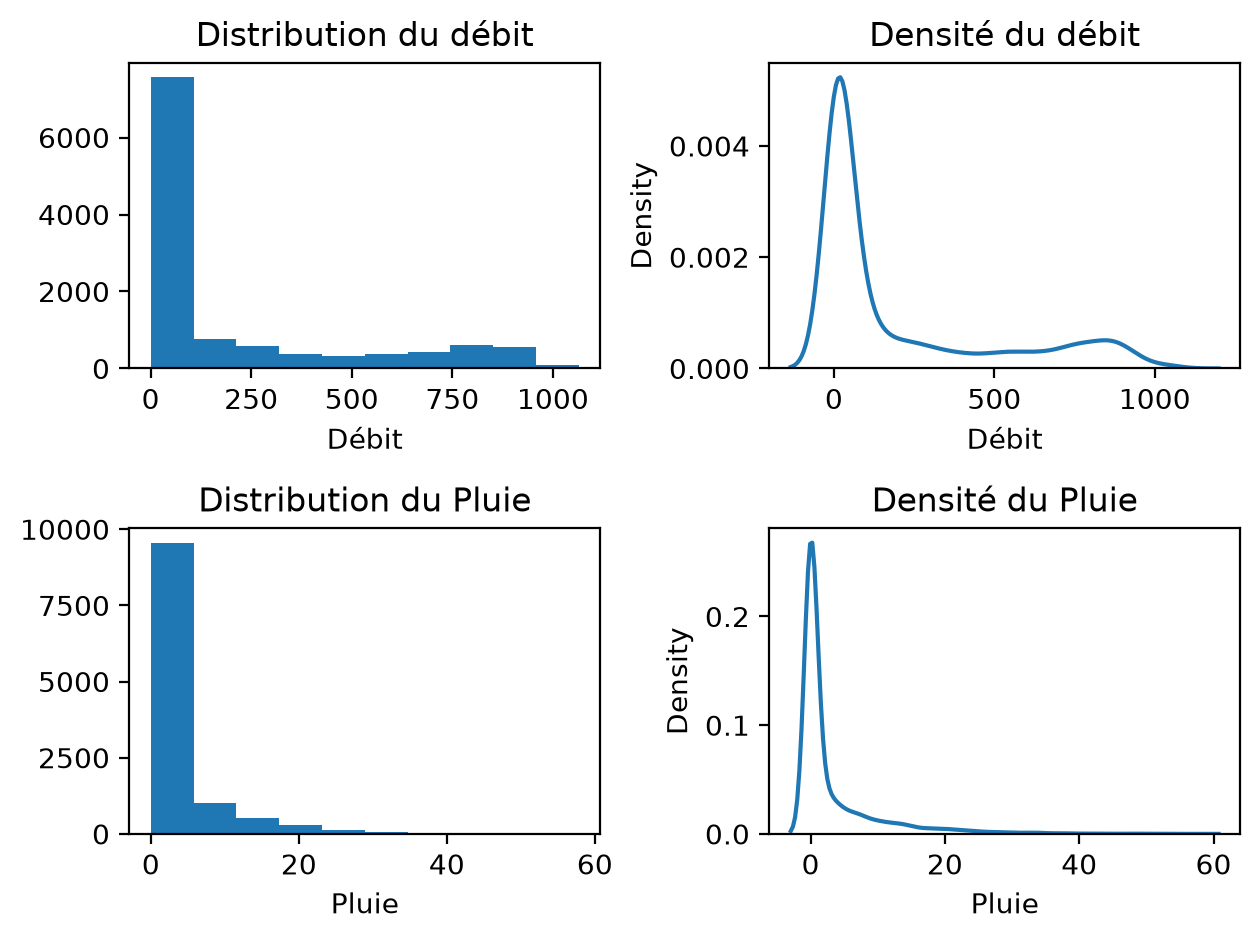

In [8]:
fig, axes=plt.subplots(2,2,dpi=200)

axes=axes.flat
axes[0].hist(data.Debit)
axes[0].set_xlabel("Débit")
axes[0].set_title("Distribution du débit")
sns.kdeplot(data.Debit,ax=axes[1])
axes[1].set_xlabel("Débit")
axes[1].set_title("Densité du débit")

axes[2].hist(data.Pluie)
axes[2].set_xlabel("Pluie")
axes[2].set_title("Distribution du Pluie")
sns.kdeplot(data.Pluie,ax=axes[3])
axes[3].set_xlabel("Pluie")
axes[3].set_title("Densité du Pluie")
plt.tight_layout()

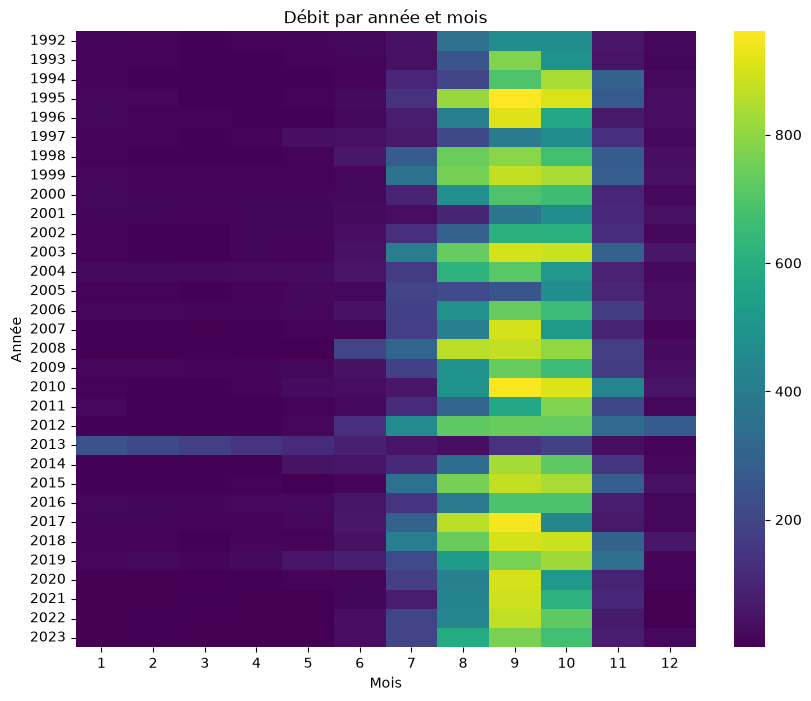

In [9]:
df = data.copy()
df["Annee"] = df["Date"].dt.year
df["Mois"] = df["Date"].dt.month
pivot =df.pivot_table(values="Debit",index="Annee",columns="Mois",aggfunc="mean")
plt.figure(figsize=(10, 8))
sns.heatmap(pivot, cmap="viridis")
plt.title("Débit par année et mois")
plt.xlabel("Mois")
plt.ylabel("Année")
plt.show()

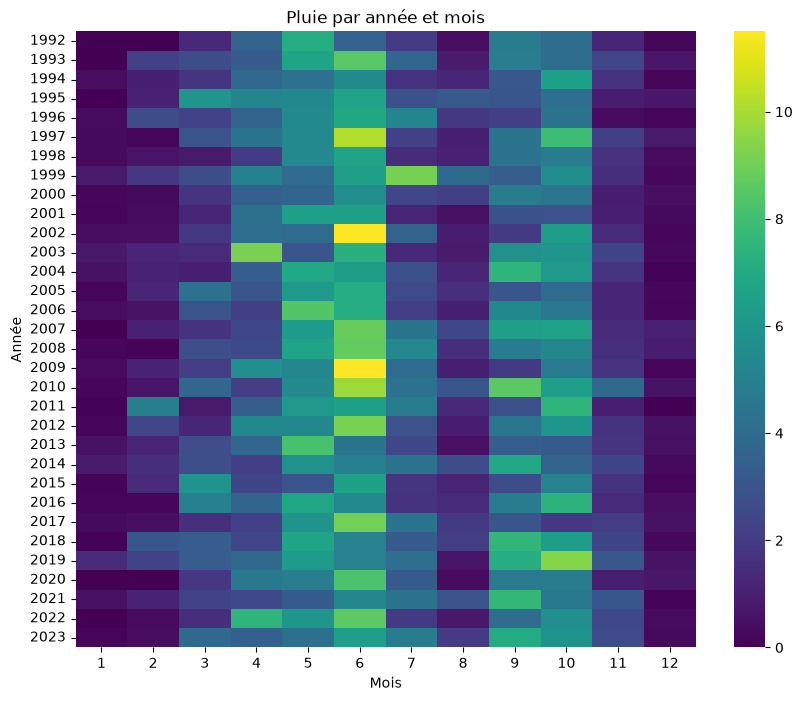

In [10]:
pivot =df.pivot_table(values="Pluie",index="Annee",columns="Mois",aggfunc="mean")
plt.figure(figsize=(10, 8))
sns.heatmap(pivot, cmap="viridis")
plt.title("Pluie par année et mois")
plt.xlabel("Mois")
plt.ylabel("Année")
plt.show()

C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_6904\3604007884.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data,x=data.Date.dt.month,y="Debit",palette="Set2",ax=axes[0])
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_6904\3604007884.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data,x=data.Date.dt.month,y="Pluie",palette="Set2",ax=axes[1])


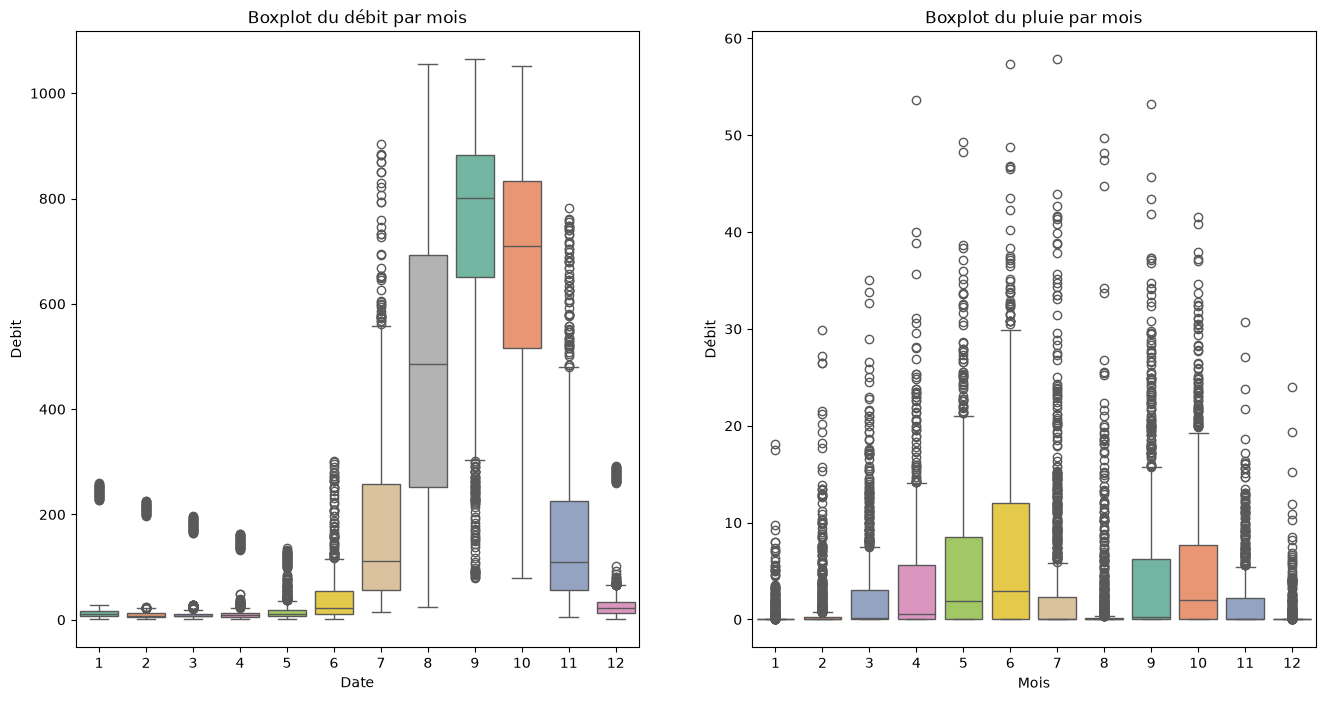

In [11]:
fig,axes=plt.subplots(1,2,figsize=(16,8))
sns.boxplot(data,x=data.Date.dt.month,y="Debit",palette="Set2",ax=axes[0])
sns.boxplot(data,x=data.Date.dt.month,y="Pluie",palette="Set2",ax=axes[1])

axes[0].set_title("Boxplot du débit par mois")
axes[1].set_title("Boxplot du pluie par mois")
plt.xlabel("Mois")
plt.ylabel("Débit")
plt.show();


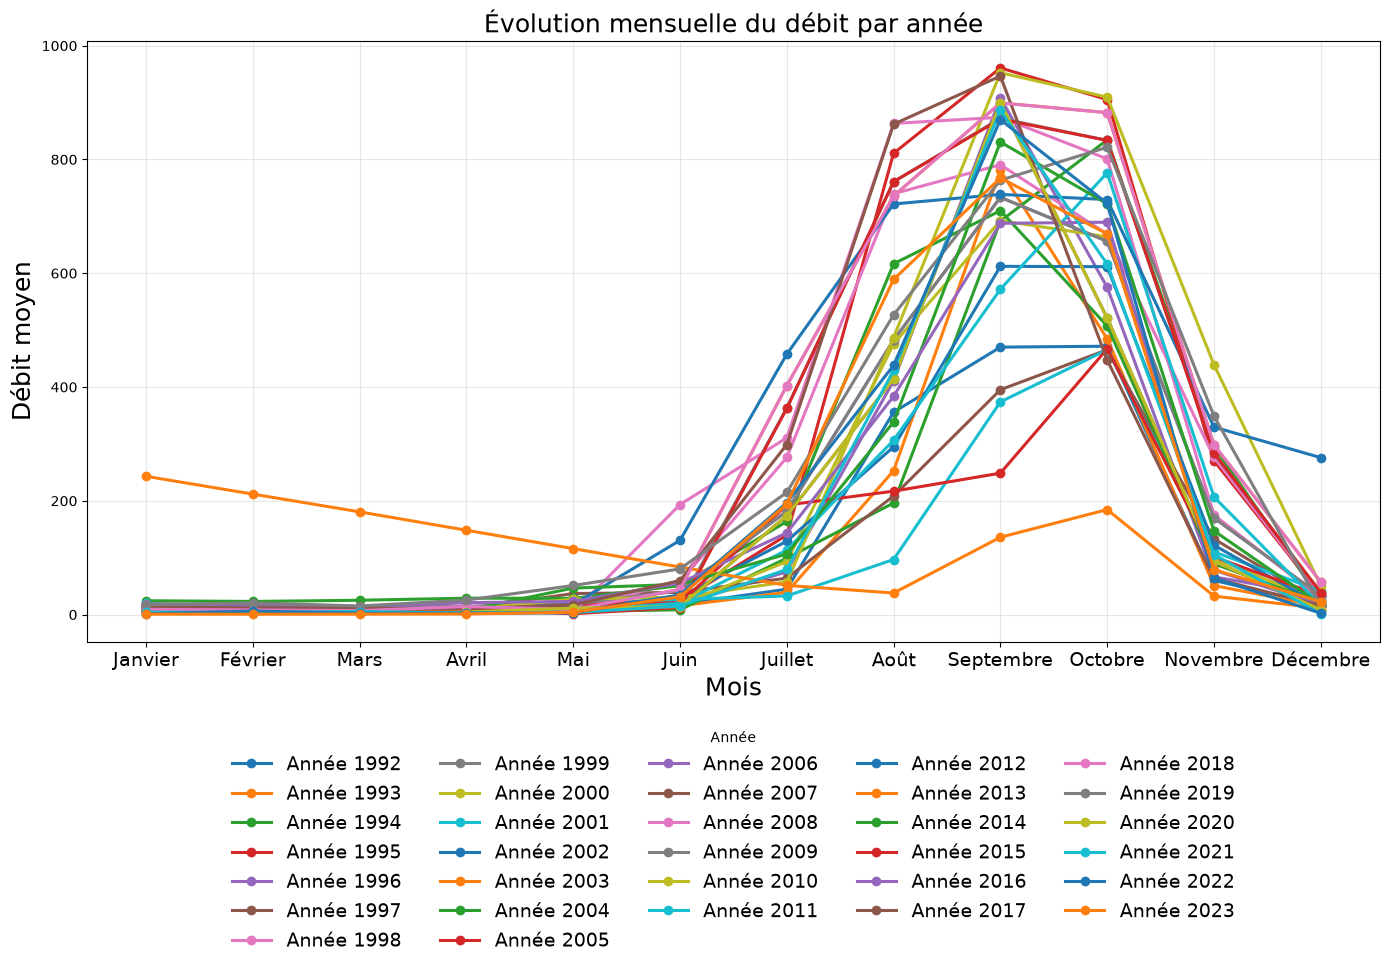

In [12]:
monthly = df.groupby(["Annee", "Mois"])["Debit"].mean().reset_index()
monthly["Mois_label"] = monthly["Mois"].astype(int)

mois_nom = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin",
            "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]

plt.figure(figsize=(14, 10))
colors = plt.cm.tab10.colors
for i, (annee, grp) in enumerate(monthly.groupby("Annee")):
    plt.plot(
        grp["Mois_label"],
        grp["Debit"],
        marker="o",
        linewidth=2.2,
        markersize=6,
        color=colors[i % len(colors)],
        label=f"Année {annee}"
    )

plt.xticks(range(1, 13), mois_nom, fontsize=14)
plt.xlabel("Mois", fontsize=18)
plt.ylabel("Débit moyen", fontsize=18)
plt.title("Évolution mensuelle du débit par année", fontsize=18)
plt.legend(title="Année", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False, fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout();

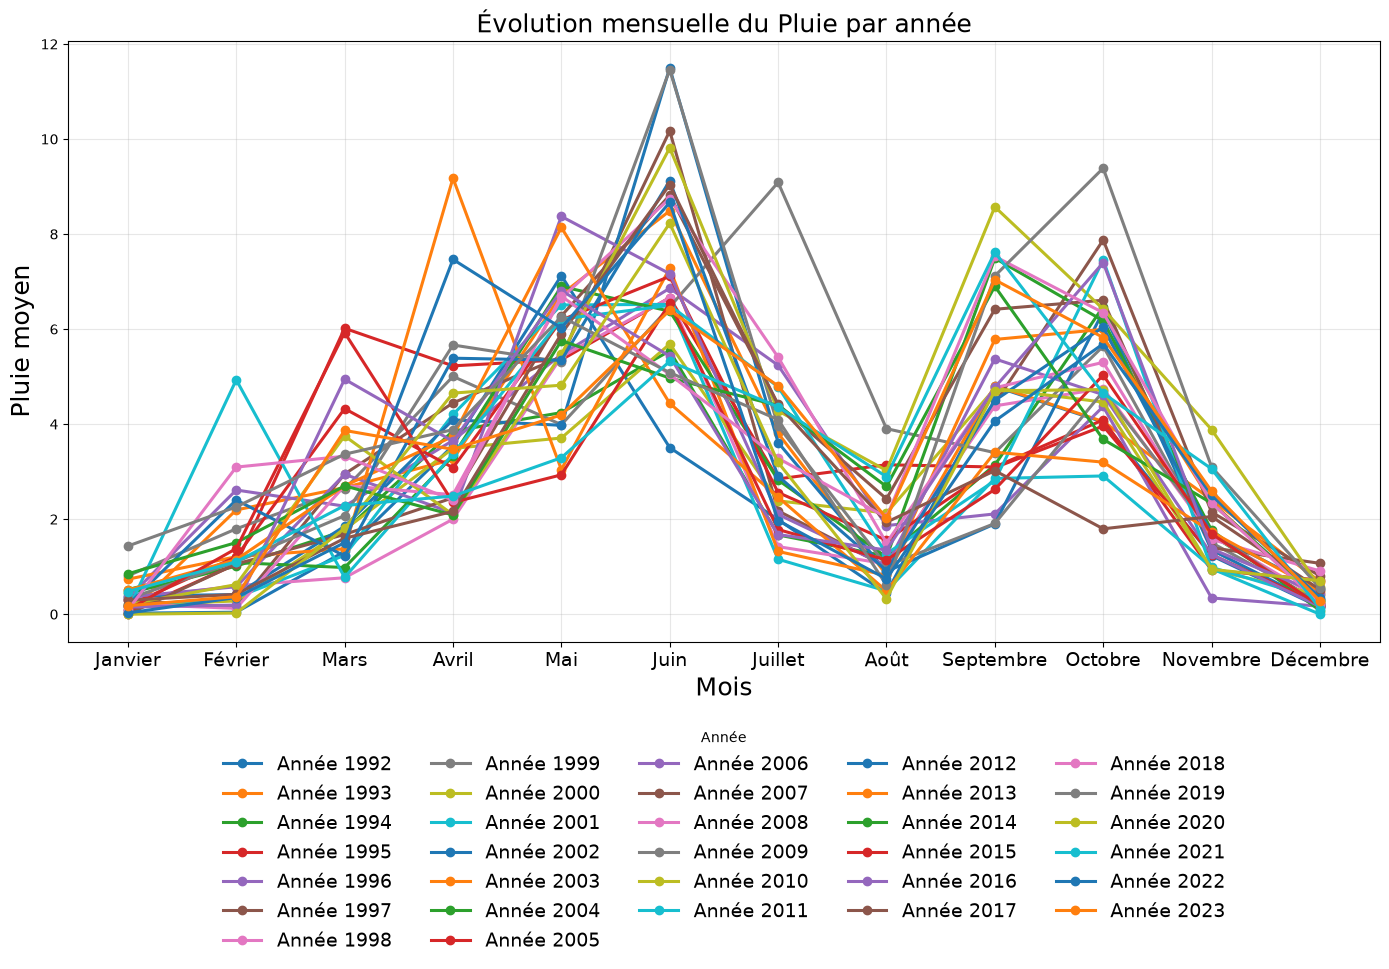

In [13]:
monthly = df.groupby(["Annee", "Mois"])["Pluie"].mean().reset_index()
monthly["Mois_label"] = monthly["Mois"].astype(int)

mois_nom = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin",
            "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]

plt.figure(figsize=(14, 10))
colors = plt.cm.tab10.colors
for i, (annee, grp) in enumerate(monthly.groupby("Annee")):
    plt.plot(
        grp["Mois_label"],
        grp["Pluie"],
        marker="o",
        linewidth=2.2,
        markersize=6,
        color=colors[i % len(colors)],
        label=f"Année {annee}"
    )

plt.xticks(range(1, 13), mois_nom, fontsize=14)
plt.xlabel("Mois", fontsize=18)
plt.ylabel("Pluie moyen", fontsize=18)
plt.title("Évolution mensuelle du Pluie par année", fontsize=18)
plt.legend(title="Année", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False, fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout();

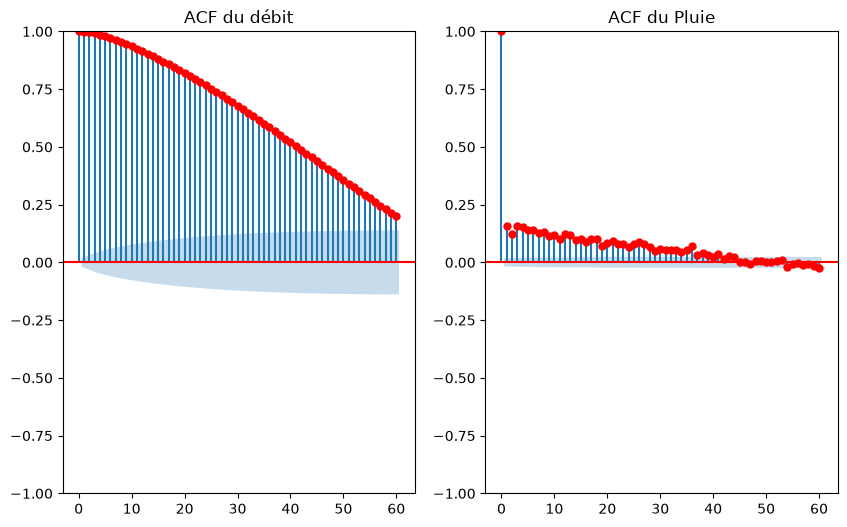

In [14]:
fig,axes=plt.subplots(1,2,figsize=(10,6))

plot_acf(data["Debit"],lags=60,title="ACF du débit",color="red",ax=axes[0])
plot_acf(data["Pluie"],lags=60,title="ACF du Pluie",color="red",ax=axes[1])

plt.show()

<Axes: >

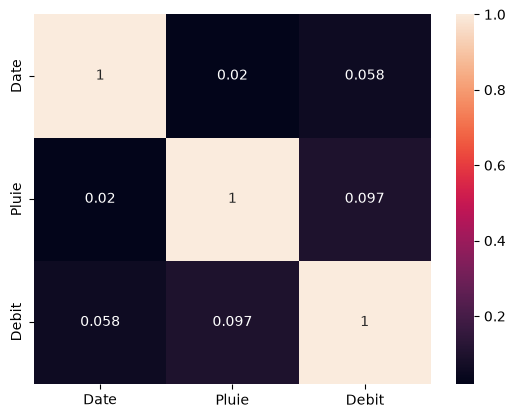

In [15]:
sns.heatmap(data.corr(),annot=True)

In [16]:
j1=[]
j2=[]
j3=[]
j4=[]
j5=[]
for i in range(len(data)):
    for j,jour in zip(range(1,6),[j1,j2,j3,j4,j5]):
        try:
            jour.append(data.loc[i+j,"Debit"])
        except:
            jour.append(np.nan)

data["Debit-j+1"]=j1
data["Debit-j+2"]=j2
data["Debit-j+3"]=j3
data["Debit-j+4"]=j4
data["Debit-j+5"]=j5

data

,Date,Pluie,Debit,Debit-j+1,Debit-j+2,Debit-j+3,Debit-j+4,Debit-j+5
0,1992-01-01,0.041684,17.280001,17.280001,17.150000,17.000000,16.889999,16.610001
1,1992-01-02,0.000000,17.280001,17.150000,17.000000,16.889999,16.610001,16.430000
2,1992-01-03,0.000000,17.150000,17.000000,16.889999,16.610001,16.430000,16.200001
3,1992-01-04,0.000000,17.000000,16.889999,16.610001,16.430000,16.200001,16.129999
4,1992-01-05,0.000000,16.889999,16.610001,16.430000,16.200001,16.129999,15.900000
...,...,...,...,...,...,...,...,...
11675,2023-12-27,0.000000,24.565679,24.022215,23.536393,23.058464,23.001593,NaN
11676,2023-12-28,0.000000,24.022215,23.536393,23.058464,23.001593,NaN,NaN
11677,2023-12-29,0.000000,23.536393,23.058464,23.001593,NaN,NaN,NaN
11678,2023-12-30,0.000000,23.058464,23.001593,NaN,NaN,NaN,NaN


In [17]:
data.loc[100-40:100,"Pluie"].mean()

np.float64(1.694705004508539)

In [18]:
j15=[]
j30=[]
j45=[]
j60=[]
j75=[]
j90=[]
for i in range(len(df2)):
    for j,jour in zip([15,30,45,60,75,90],[j15,j30,j45,j60,j75,j90]):
        jour.append(df2.loc[i-j:i,"BONOU"].sum())

df2["Cum_Pluie_15"]=j15
df2["Cum_Pluie_30"]=j30
df2["Cum_Pluie_45"]=j45
df2["Cum_Pluie_60"]=j60
df2["Cum_Pluie_75"]=j75
df2["Cum_Pluie_90"]=j90

df=df2[((1992<=df2.date.dt.year) & (df2.date.dt.year<=2023))]
df=df[~((df2.date.dt.month==2) & (df2.date.dt.day==29))]

data["Cum_Pluie_15"]=df2["Cum_Pluie_15"]
data["Cum_Pluie_30"]=df2["Cum_Pluie_30"]
data["Cum_Pluie_45"]=df2["Cum_Pluie_45"]
data["Cum_Pluie_60"]=df2["Cum_Pluie_60"]
data["Cum_Pluie_75"]=df2["Cum_Pluie_75"]
data["Cum_Pluie_90"]=df2["Cum_Pluie_90"]
data

C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_6904\1104609689.py:19: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df=df[~((df2.date.dt.month==2) & (df2.date.dt.day==29))]


,Date,Pluie,Debit,Debit-j+1,Debit-j+2,Debit-j+3,Debit-j+4,Debit-j+5,Cum_Pluie_15,Cum_Pluie_30,Cum_Pluie_45,Cum_Pluie_60,Cum_Pluie_75,Cum_Pluie_90
0,1992-01-01,0.041684,17.280001,17.280001,17.150000,17.000000,16.889999,16.610001,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
1,1992-01-02,0.000000,17.280001,17.150000,17.000000,16.889999,16.610001,16.430000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
2,1992-01-03,0.000000,17.150000,17.000000,16.889999,16.610001,16.430000,16.200001,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
3,1992-01-04,0.000000,17.000000,16.889999,16.610001,16.430000,16.200001,16.129999,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
4,1992-01-05,0.000000,16.889999,16.610001,16.430000,16.200001,16.129999,15.900000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11675,2023-12-27,0.000000,24.565679,24.022215,23.536393,23.058464,23.001593,NaN,7.645776,25.424902,48.008249,94.470788,146.31320,241.870104
11676,2023-12-28,0.000000,24.022215,23.536393,23.058464,23.001593,NaN,NaN,7.645776,20.283536,46.192599,94.470788,146.31320,234.764386
11677,2023-12-29,0.000000,23.536393,23.058464,23.001593,NaN,NaN,NaN,7.645776,20.283536,40.883352,89.848112,141.37339,229.588612
11678,2023-12-30,0.000000,23.058464,23.001593,NaN,NaN,NaN,NaN,7.645776,19.943876,33.990252,89.848112,141.37339,221.738308


<Axes: >

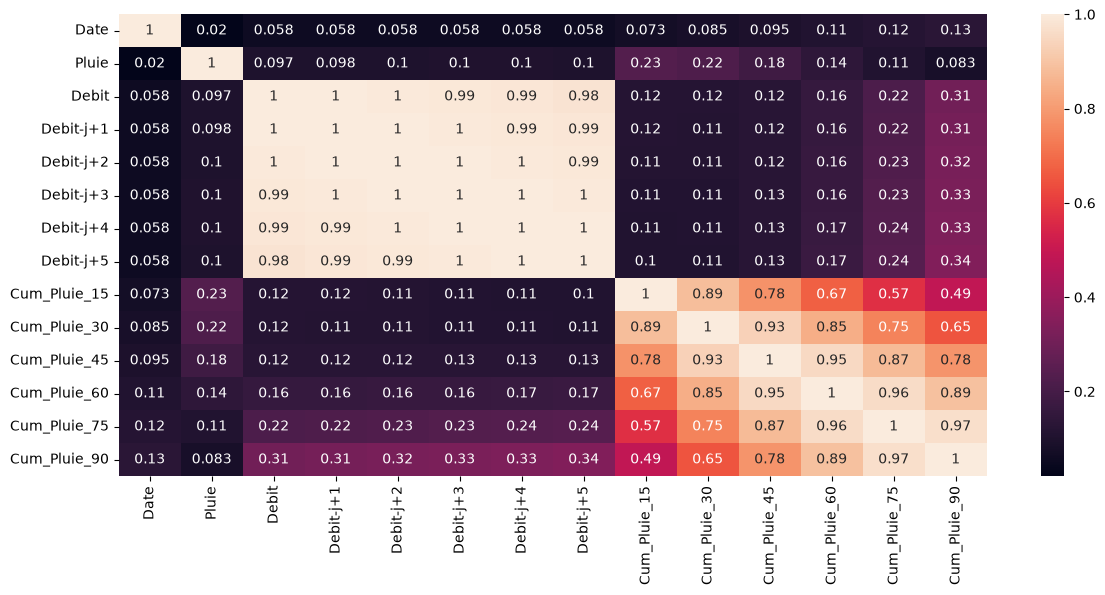

In [19]:
plt.figure(figsize=(14,6))
sns.heatmap(data.corr(),annot=True)

In [20]:
j1=[]
j2=[]
j3=[]
j4=[]
j5=[]
for i in range(len(data)):
    for j,jour in zip(range(1,6),[j1,j2,j3,j4,j5]):
        try:
            jour.append(data.loc[i-j,"Debit"])
        except:
            jour.append(np.nan)

data["Debit-j-1"]=j1
data["Debit-j-2"]=j2
data["Debit-j-3"]=j3
data["Debit-j-4"]=j4
data["Debit-j-5"]=j5

data

,Date,Pluie,Debit,Debit-j+1,Debit-j+2,Debit-j+3,Debit-j+4,Debit-j+5,Cum_Pluie_15,Cum_Pluie_30,Cum_Pluie_45,Cum_Pluie_60,Cum_Pluie_75,Cum_Pluie_90,Debit-j-1,Debit-j-2,Debit-j-3,Debit-j-4,Debit-j-5
0,1992-01-01,0.041684,17.280001,17.280001,17.150000,17.000000,16.889999,16.610001,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,NaN,NaN,NaN,NaN,NaN
1,1992-01-02,0.000000,17.280001,17.150000,17.000000,16.889999,16.610001,16.430000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,17.280001,NaN,NaN,NaN,NaN
2,1992-01-03,0.000000,17.150000,17.000000,16.889999,16.610001,16.430000,16.200001,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,17.280001,17.280001,NaN,NaN,NaN
3,1992-01-04,0.000000,17.000000,16.889999,16.610001,16.430000,16.200001,16.129999,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,17.150000,17.280001,17.280001,NaN,NaN
4,1992-01-05,0.000000,16.889999,16.610001,16.430000,16.200001,16.129999,15.900000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,17.000000,17.150000,17.280001,17.280001,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11675,2023-12-27,0.000000,24.565679,24.022215,23.536393,23.058464,23.001593,NaN,7.645776,25.424902,48.008249,94.470788,146.31320,241.870104,25.140571,25.837714,26.551107,27.233536,27.854750
11676,2023-12-28,0.000000,24.022215,23.536393,23.058464,23.001593,NaN,NaN,7.645776,20.283536,46.192599,94.470788,146.31320,234.764386,24.565679,25.140571,25.837714,26.551107,27.233536
11677,2023-12-29,0.000000,23.536393,23.058464,23.001593,NaN,NaN,NaN,7.645776,20.283536,40.883352,89.848112,141.37339,229.588612,24.022215,24.565679,25.140571,25.837714,26.551107
11678,2023-12-30,0.000000,23.058464,23.001593,NaN,NaN,NaN,NaN,7.645776,19.943876,33.990252,89.848112,141.37339,221.738308,23.536393,24.022215,24.565679,25.140571,25.837714


In [21]:
j15=[]
j30=[]
j45=[]
j60=[]
j75=[]
j90=[]
for i in range(len(df2)):
    for j,jour in zip([110,130,150,170,180,200],[j15,j30,j45,j60,j75,j90]):
        jour.append(df2.loc[i-j:i,"BONOU"].sum())

df2["Cum_Pluie_110"]=j15
df2["Cum_Pluie_130"]=j30
df2["Cum_Pluie_150"]=j45
df2["Cum_Pluie_170"]=j60
df2["Cum_Pluie_180"]=j75
df2["Cum_Pluie_200"]=j90

df=df2[((1992<=df2.date.dt.year) & (df2.date.dt.year<=2023))]
df=df[~((df2.date.dt.month==2) & (df2.date.dt.day==29))]

data["Cum_Pluie_110"]=df2["Cum_Pluie_110"]
data["Cum_Pluie_130"]=df2["Cum_Pluie_130"]
data["Cum_Pluie_150"]=df2["Cum_Pluie_150"]
data["Cum_Pluie_170"]=df2["Cum_Pluie_170"]
data["Cum_Pluie_180"]=df2["Cum_Pluie_180"]
data["Cum_Pluie_200"]=df2["Cum_Pluie_200"]
data

C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_6904\532577040.py:19: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df=df[~((df2.date.dt.month==2) & (df2.date.dt.day==29))]


,Date,Pluie,Debit,Debit-j+1,Debit-j+2,Debit-j+3,Debit-j+4,Debit-j+5,Cum_Pluie_15,Cum_Pluie_30,...,Debit-j-2,Debit-j-3,Debit-j-4,Debit-j-5,Cum_Pluie_110,Cum_Pluie_130,Cum_Pluie_150,Cum_Pluie_170,Cum_Pluie_180,Cum_Pluie_200
0,1992-01-01,0.041684,17.280001,17.280001,17.150000,17.000000,16.889999,16.610001,0.000000,0.000000,...,NaN,NaN,NaN,NaN,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1992-01-02,0.000000,17.280001,17.150000,17.000000,16.889999,16.610001,16.430000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
2,1992-01-03,0.000000,17.150000,17.000000,16.889999,16.610001,16.430000,16.200001,0.000000,0.000000,...,17.280001,NaN,NaN,NaN,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
3,1992-01-04,0.000000,17.000000,16.889999,16.610001,16.430000,16.200001,16.129999,0.000000,0.000000,...,17.280001,17.280001,NaN,NaN,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
4,1992-01-05,0.000000,16.889999,16.610001,16.430000,16.200001,16.129999,15.900000,0.000000,0.000000,...,17.150000,17.280001,17.280001,NaN,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11675,2023-12-27,0.000000,24.565679,24.022215,23.536393,23.058464,23.001593,NaN,7.645776,25.424902,...,25.837714,26.551107,27.233536,27.854750,261.83371,277.005812,291.180276,352.174766,367.292197,483.432330
11676,2023-12-28,0.000000,24.022215,23.536393,23.058464,23.001593,NaN,NaN,7.645776,20.283536,...,25.140571,25.837714,26.551107,27.233536,261.83371,277.005812,291.180276,350.509517,367.292197,476.422075
11677,2023-12-29,0.000000,23.536393,23.058464,23.001593,NaN,NaN,NaN,7.645776,20.283536,...,24.565679,25.140571,25.837714,26.551107,261.83371,277.005812,291.180276,328.398215,367.292197,471.437380
11678,2023-12-30,0.000000,23.058464,23.001593,NaN,NaN,NaN,NaN,7.645776,19.943876,...,24.022215,24.565679,25.140571,25.837714,261.83371,277.005812,279.353508,319.151485,364.814209,471.437380


<Axes: >

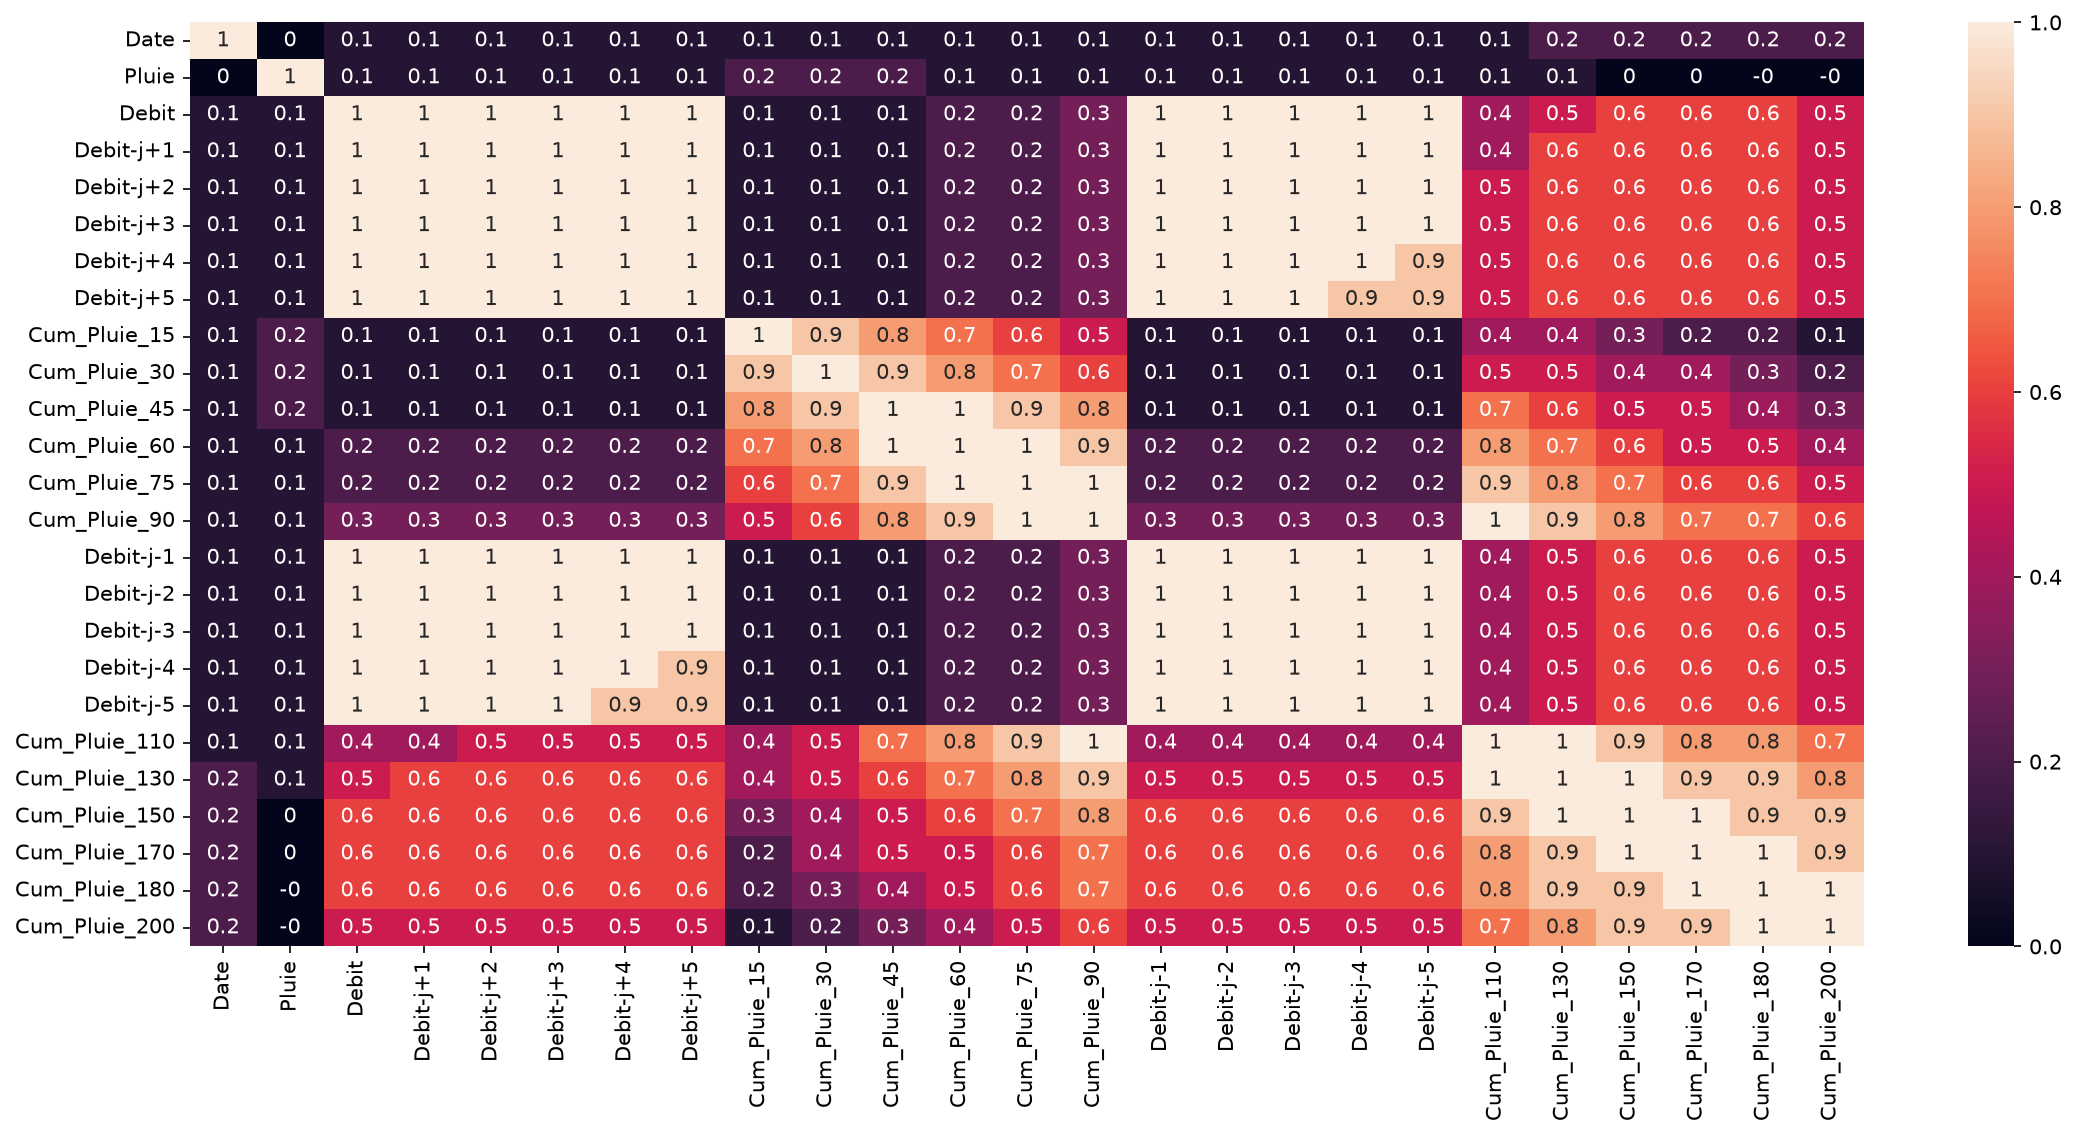

In [22]:
plt.figure(figsize=(18,8),dpi=150)
sns.heatmap(round(data.corr(),1),annot=True)

In [23]:
data.to_excel("Data//DonneePreModel.xlsx",index=False)